# 05 - Reconstructed WML: stock turnover and transaction costs

**Question:** Do risk scaling, crash protection and net performance resemble Barroso and Santa-Clara (2015) when WML is reconstructed from stocks and charged stock-level trading costs?

**Workflow:** (1) load Notebook 03's fingerprinted build; (2) check monthly valuations and daily risk coverage; (3) compare KF and rebuilt gross returns on identical calendars; (4) calculate stock entries, exits and drift using Appendix B's leg normalization; (5) charge adjustable costs and reconcile funded stock trades; (6) compare observations with the paper and the post-sample extension.

**Read this qualification first:** Complete performance tables use the **published-return stock reference with shared KF risk weights**. They are a controlled comparison, not a complete independent stock-risk replication. Ordinary stock return gaps are zero under the accepted research assumption. Unknown terminal payoffs are protected in the strict DM variant; the complete reference retains numeric published returns without claiming all terminal values are confirmed. Missing own-risk forecasts are never replaced with cash.

**Sources and rules**
- Stock membership/weights/returns: WRDS CRSP CIZ annual caches, reconstructed by the current `wml_pipeline` API used in Notebook 03. US ordinary shares, historical share/exchange eligibility, NYSE 12-2 momentum deciles, prior-month value weights, period-end price/date screens at formation and t-13. Flag details: `CIZ_FLAGS.md`; reconstruction details: `WML_PIPELINE.md`.
- Benchmark: cached [Kenneth French monthly deciles](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_port_form_pr_12_2.html) and [daily deciles](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_10_port_form_pr_12_2_daily.html), P10 minus P1, percent converted to decimals.
- [Barroso and Santa-Clara (2015)](https://doi.org/10.1016/j.jfineco.2014.11.010): Section 4, Appendix B equations 8-10. The locally supplied manuscript reports turnover on **1951-03 to 2010-12**: 74% unmanaged, 75% managed, and 127/175bp roundtrip costs to remove 5% significance. These are published reference values, not calibration targets.
- [Daniel-Moskowitz data notes](https://www.kentdaniel.net/data/momentum/mom_data.pdf): monthly-formed daily portfolios and delisting returns. Known excluded terminal payoffs are included once; already included payoffs are not added again. Unresolved final values are not officially zero.

**Windows:** 1927-05 to 2011-12 (available common historical sample); 1951-03 to 2010-12 (paper's distinct turnover test); 2012-01 to 2025-12 (disjoint post-sample extension, not entirely post-publication). The original March-April 1927 performance months are unavailable with the public KF daily warm-up and are not silently backfilled. No removed auxiliary windows are reintroduced.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/momentum_risk_project").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
from momentum_risk_project.wml_pipeline import load_build, estimate_risk, file_sha256
from momentum_risk_project.data import clean_momentum
from run_stock_cost_study import run_study, WINDOWS

COST_BPS_PER_DOLLAR = (0, 5, 10, 25, 50)
BASELINE_COST_BPS = 10
RERUN_STUDY = False  # True recomputes the full stock study; otherwise verify saved results.
OUT = ROOT / "outputs/05_stock_backtest"
if RERUN_STUDY or not (OUT / "run.json").exists():
    run_study(ROOT, costs=COST_BPS_PER_DOLLAR)
manifest = json.loads((OUT / "run.json").read_text())
assert manifest["cost_bps_per_dollar"] == list(COST_BPS_PER_DOLLAR)
for paths in [manifest["input_sha256"], manifest["code_sha256"]]:
    for name, digest in paths.items():
        assert file_sha256(ROOT / name) == digest, f"Stale study: {name}; set RERUN_STUDY=True"
build = load_build(ROOT / "data/processed/wml_current_v1_20261031")
metrics = pd.read_csv(OUT / "metrics.csv")
turnover = pd.read_csv(OUT / "turnover.csv")

def show(title, frame):
    print(title)
    formats = {k: "{:.2%}" for k in ["Annualized Mean Return", "Annualized Volatility", "CAGR", "Maximum Drawdown", "Worst month", "Annual trading cost", "Mean absolute traded notional", "scaled_positions_mean_half_turnover", "literal_eq10_mean_half_turnover"] if k in frame}
    formats.update({k:"{:.3f}" for k in ["Sharpe (rf=0)", "Skewness", "Excess kurtosis"] if k in frame})
    display(frame.style.format(formats, na_rep="Unavailable"))

show("Table 1 - Evaluation calendars (identical within each comparison)",
     pd.DataFrame([dict(window=k, start=a, end=z, months=len(pd.period_range(a,z,freq="M"))) for k,(a,z) in WINDOWS.items()]))

Table 1 - Evaluation calendars (identical within each comparison)


,window,start,end,months
0,paper_available_common,1927-05,2011-12,1016
1,paper_turnover_test,1951-03,2010-12,718
2,extension_disjoint,2012-01,2025-12,168


## 1. Valuation and risk: what can actually be evaluated?

Monthly returns are P10 minus P1 monthly simple total returns; daily long-short returns are **not** compounded to manufacture monthly WML. At factor weight one, long notional is 1 and short notional is 1 (gross exposure 2).

Risk uses $\hat\sigma_t=\sqrt{21\,\mathrm{mean}_{126}(r_{d}^{2})}$, with no demeaning; next month's factor weight is $L_{t+1}=(0.12/\sqrt{12})/\hat\sigma_t$. The final trading day of the prior month supplies the forecast. Unknown daily observations remain unknown. Monthly membership in the stock daily series differs from KF's daily reformation.

The following table distinguishes isolated known monthly returns, complete risk forecasts and an uninterrupted strict account. They are not interchangeable coverage counts. The strict account stops at its first unresolved holding; later known returns do not restart the same wealth history.

In [2]:
coverage = pd.read_csv(OUT / "coverage.csv")
show("Table 2 - Strict coverage; missing risk is not cash", coverage)
months = pd.period_range("1927-05", "2025-12", freq="M")
kf_daily = clean_momentum(pd.read_parquet(ROOT / "data/raw/02_kf_momentum_deciles_daily_vw.parquet"), "daily").mom
shared_risk = estimate_risk(kf_daily, months)
own_risk = estimate_risk(build.daily.WML, months)
assert shared_risk.forecast_available.all()
assert own_risk.forecast_available.sum() == coverage.loc[coverage.window.ne("paper_turnover_test"), "own_stock_risk_forecasts"].sum()
print("Complete results below explicitly use published_reference valuations and shared KF risk.")

Table 2 - Strict coverage; missing risk is not cash


,window,start,end,months,own_stock_risk_forecasts,strict_DM_monthly_returns,strict_continuous_account_known_months,cash_fill_used
0,paper_available_common,1927-05,2011-12,1016,0,566,35,False
1,paper_turnover_test,1951-03,2010-12,718,0,311,0,False
2,extension_disjoint,2012-01,2025-12,168,0,109,0,False


Complete results below explicitly use published_reference valuations and shared KF risk.


## 2. KF versus reconstructed gross performance

Both return series use exactly the same dates and the same lagged KF risk weights. This isolates the monthly reconstruction difference. Results use arithmetic annual means and sample volatility, Sharpe relative to zero, compound feasible wealth, maximum drawdown including initial wealth, skewness and excess kurtosis. These long-short strategy statistics exclude collateral interest.

Each plotted window is rebased to wealth one. Extension returns come from the uninterrupted strategy; there is no artificial new position entry at 2012-01.

Table 3 - Complete conditional gross returns: KF and rebuilt WML


,window,strategy,Annualized Mean Return,Annualized Volatility,Sharpe (rf=0),CAGR,Maximum Drawdown,Worst month,Skewness,Excess kurtosis
0,paper_available_common,KF unmanaged,14.86%,27.42%,0.542,10.65%,-95.56%,-77.66%,-2.388,18.044
1,paper_available_common,Rebuilt reference unmanaged,14.86%,27.48%,0.541,10.61%,-95.44%,-78.11%,-2.420,18.331
2,paper_available_common,KF managed,16.69%,16.77%,0.996,16.40%,-43.83%,-24.16%,-0.356,2.014
3,paper_available_common,Rebuilt reference managed,16.72%,16.80%,0.995,16.42%,-43.48%,-24.69%,-0.359,2.115
4,paper_turnover_test,KF unmanaged,16.20%,22.74%,0.712,14.25%,-80.84%,-45.18%,-1.511,8.850
5,paper_turnover_test,Rebuilt reference unmanaged,16.08%,22.73%,0.707,14.12%,-81.48%,-45.03%,-1.552,8.870
6,paper_turnover_test,KF managed,19.71%,17.10%,1.153,19.87%,-27.65%,-16.93%,-0.171,1.104
7,paper_turnover_test,Rebuilt reference managed,19.73%,17.12%,1.152,19.88%,-28.34%,-16.93%,-0.160,1.163
8,extension_disjoint,KF unmanaged,4.01%,27.17%,0.148,0.12%,-64.77%,-32.08%,-0.902,2.553
9,extension_disjoint,Rebuilt reference unmanaged,4.63%,27.15%,0.171,0.76%,-63.29%,-29.57%,-0.859,2.148


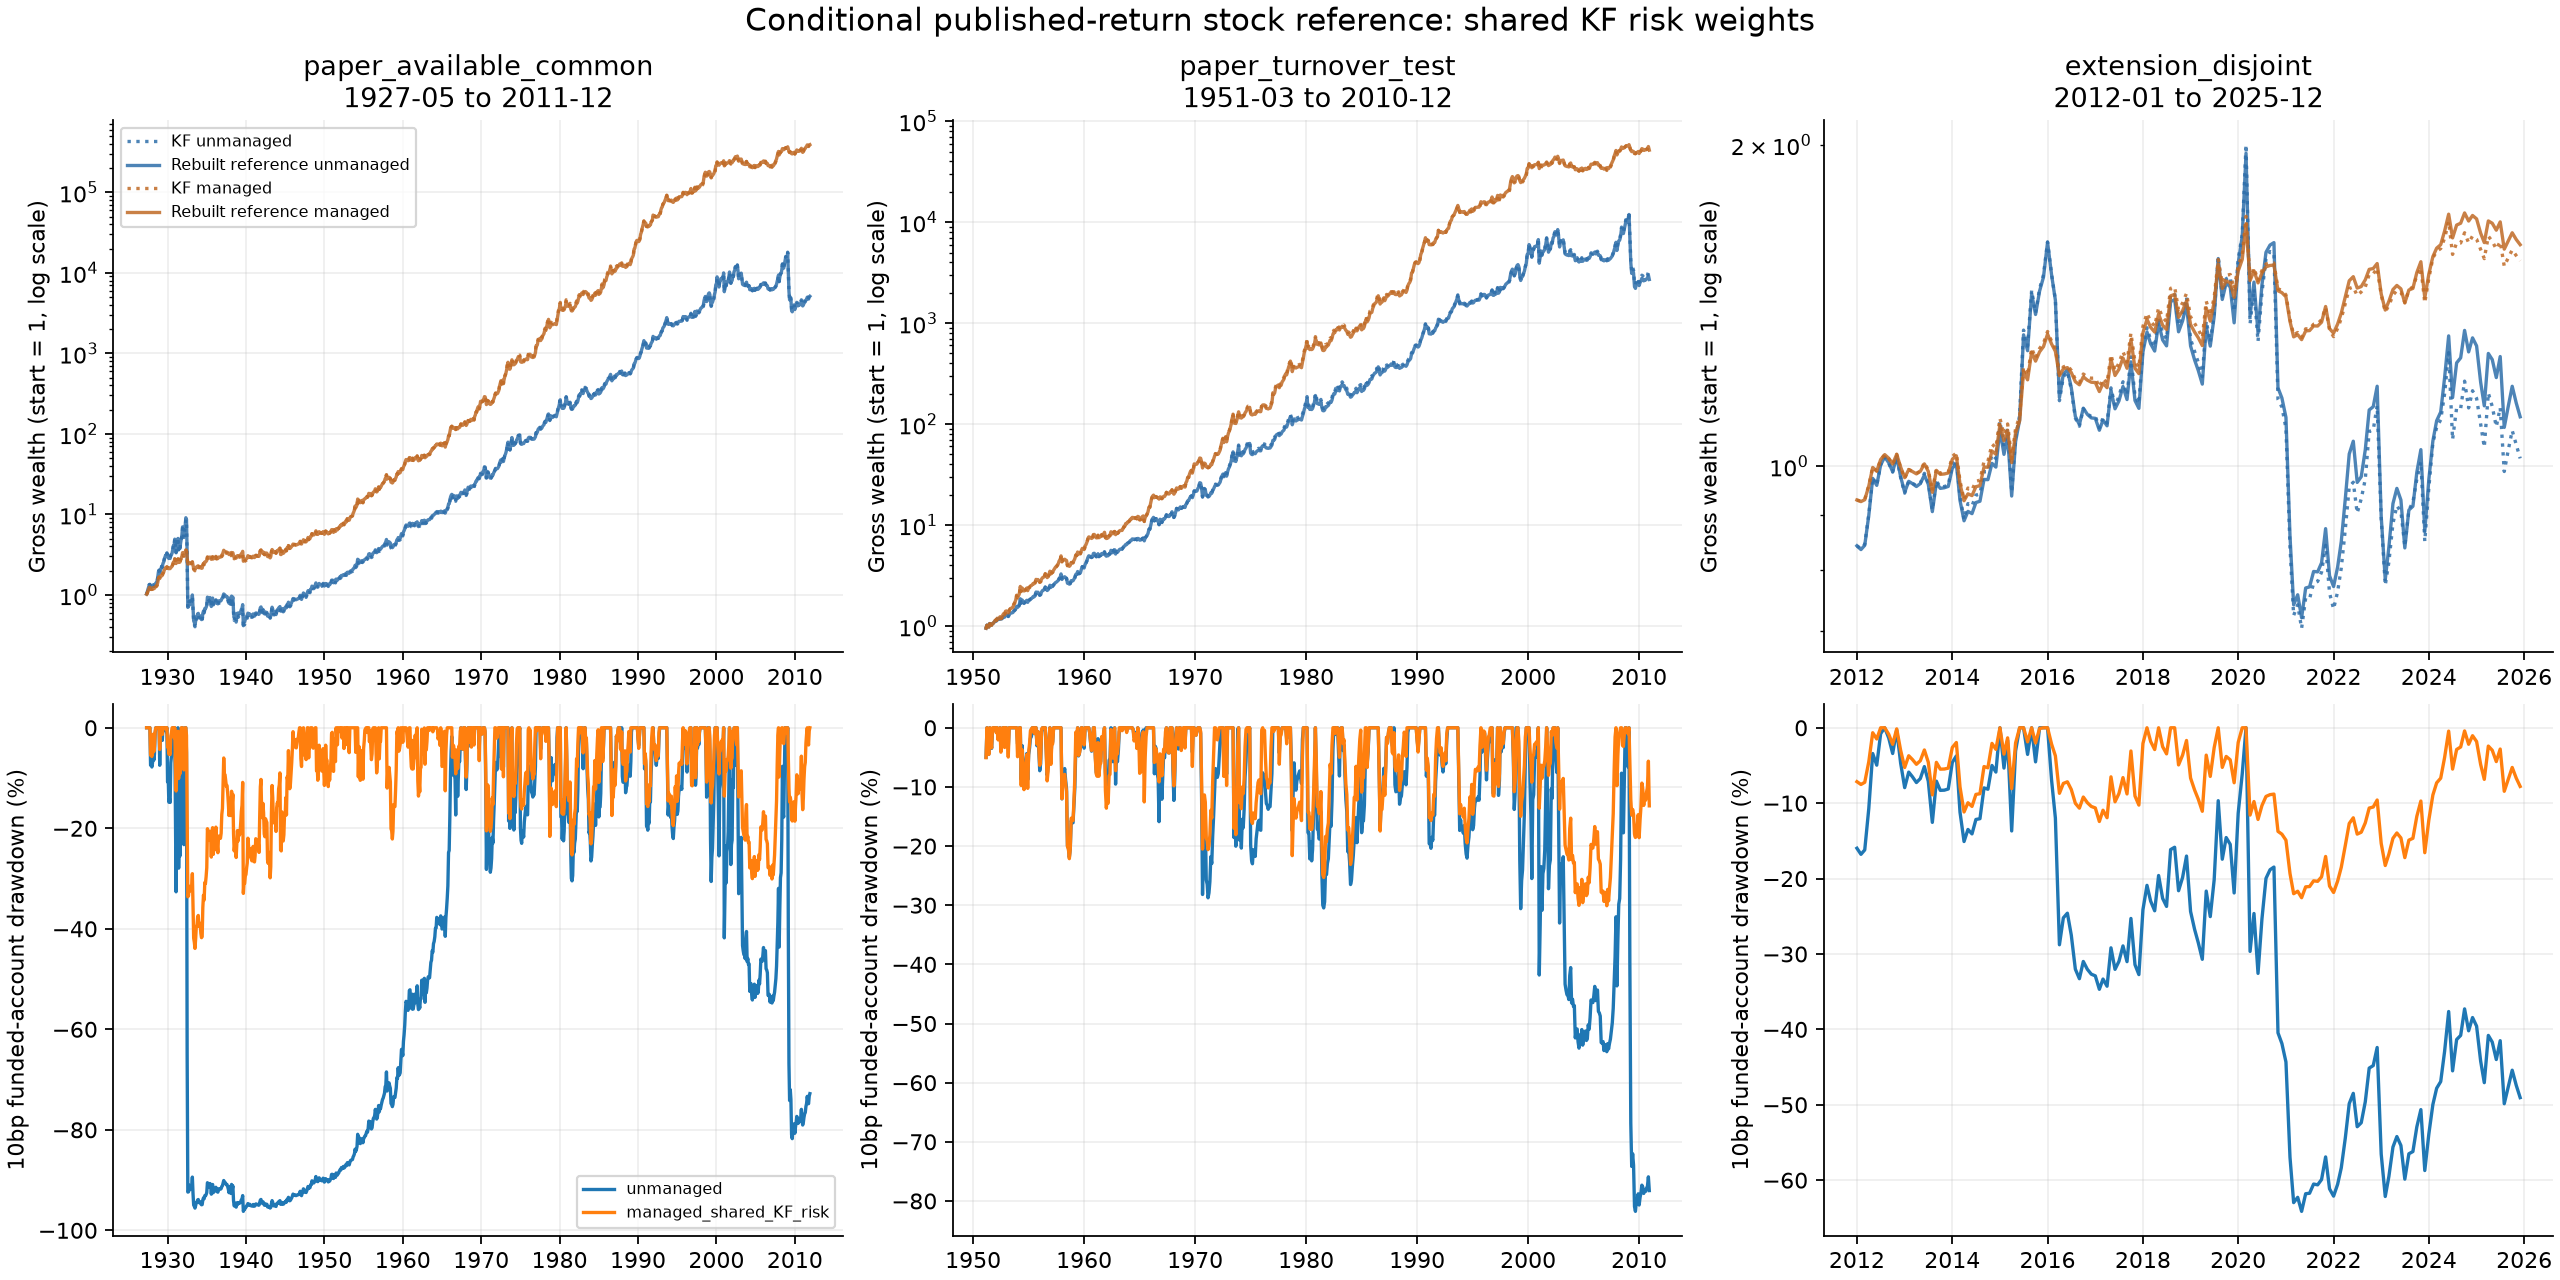

In [3]:
performance_columns = ["window", "strategy", "Annualized Mean Return", "Annualized Volatility", "Sharpe (rf=0)", "CAGR", "Maximum Drawdown", "Worst month", "Skewness", "Excess kurtosis"]
show("Table 3 - Complete conditional gross returns: KF and rebuilt WML", metrics.loc[metrics.method.eq("gross"), performance_columns])
display(Image(filename=str(OUT / "wealth_and_drawdown.png")))

## 3. Appendix B turnover: stock entries, exits and drift

For each leg, let $u_{i,t}$ be the normalized stock target, with $\sum_i u_{i,t}=1$. Before trading, the previous month's total returns produce

$$\tilde u_{i,t-1}=\frac{u_{i,t-1}(1+r_{i,t-1})}{\sum_j u_{j,t-1}(1+r_{j,t-1})}.$$

Unmanaged turnover is $\frac12\sum_i|u_{i,t}-\tilde u_{i,t-1}|$, summed over both legs. We include the union of prior and current names; a leg switch has an exit and an entry. This is **stock turnover**, not the factor multiplier-change proxy.

**Managed-formula qualification:** The supplied manuscript prints $u_{i,t}/L_t-\tilde u_{i,t-1}/L_{t-1}$ inside equation 10's absolute value, even though strategy returns scale by $L_t=\sigma_{target}/\hat\sigma_t$. We retain that **literal inverse-L diagnostic**. The separate **scaled_positions** diagnostic uses $L_tu_{i,t}-L_{t-1}\tilde u_{i,t-1}$, consistent with actual strategy exposure. We do not assert the discrepancy is an officially corrected typo or claim an exact match to author code.

Initial establishment is charged once in May 1927 but excluded from steady-state average turnover. No terminal liquidation is charged. This normalization differs from the funded account's common-NAV denominator, so its turnover need not equal half of funded-account trades.

In [4]:
show("Table 4 - Mean monthly leg-normalized half-turnover; two managed conventions", turnover)
print("Paper turnover-test reference: 74% unmanaged / 75% managed, March 1951 to December 2010.")
print("These reference numbers are not full-sample or extension targets.")

Table 4 - Mean monthly leg-normalized half-turnover; two managed conventions


,window,strategy,months,turnover_mean_months,scaled_positions_mean_half_turnover,literal_eq10_mean_half_turnover
0,paper_available_common,unmanaged,1016,1015,74.66%,74.66%
1,paper_turnover_test,unmanaged,718,718,71.32%,71.32%
2,extension_disjoint,unmanaged,168,168,72.02%,72.02%
3,paper_available_common,managed_shared_KF_risk,1016,1015,67.63%,115.08%
4,paper_turnover_test,managed_shared_KF_risk,718,718,73.40%,92.61%
5,extension_disjoint,managed_shared_KF_risk,168,168,37.05%,168.52%


Paper turnover-test reference: 74% unmanaged / 75% managed, March 1951 to December 2010.
These reference numbers are not full-sample or extension targets.


## 4. Costs and a self-funded stock account

`transaction_cost_bps` is a **one-way rate per dollar traded**. For the Appendix B half-turnover $x_t$, the corresponding roundtrip rate is twice that number, so diagnostic net return is $r_t-(2c)x_t$ for decimal one-way rate $c$. A 10bp one-way fee means a 20bp roundtrip fee, not 10bp times half-turnover.

The funded account instead charges actual buy/sell notional. Targets are fractions of after-fee NAV; with pretrade positions $p_i$, targets $q_i$ and after-fee NAV fraction $z$, it solves

$$z+c\sum_i|zq_i-p_i|=1.$$

Total returns drive profit; ex-distribution returns drive stock price drift, with distributions allocated to cash at monthly resolution. Known delistings settle once. Endogenous costs change next month's NAV and trade amounts. This is an explicit implementation sensitivity, not Appendix B's normalized-leg accounting. The two methods are shown separately.

Financing is zero in this study. Short borrow, rebates, intramonth distribution timing, capacity/market impact variation and delayed payoff cash dates are not identified by these inputs. The complete published-return reference is conditional on uncertain terminal valuations.

Table 5 - Net performance at 10bp per dollar traded (20bp roundtrip diagnostic)


,method,window,strategy,Annualized Mean Return,Annualized Volatility,Sharpe (rf=0),CAGR,Maximum Drawdown,Worst month,Skewness,Excess kurtosis,Mean absolute traded notional,Annual trading cost
30,appendix_scaled_positions,paper_available_common,unmanaged,13.07%,27.48%,0.476,8.65%,-96.17%,-78.23%,-2.423,18.345,Unavailable,Unavailable
31,appendix_scaled_positions,paper_turnover_test,unmanaged,14.37%,22.73%,0.632,12.20%,-81.72%,-45.14%,-1.551,8.878,Unavailable,Unavailable
32,appendix_scaled_positions,extension_disjoint,unmanaged,2.90%,27.16%,0.107,-0.97%,-64.05%,-29.66%,-0.855,2.127,Unavailable,Unavailable
36,funded_account,paper_available_common,unmanaged,13.00%,27.45%,0.474,8.59%,-96.22%,-78.26%,-2.428,18.394,153.63%,1.84%
37,funded_account,paper_turnover_test,unmanaged,14.32%,22.70%,0.631,12.15%,-81.76%,-45.20%,-1.554,8.898,144.59%,1.74%
38,funded_account,extension_disjoint,unmanaged,2.84%,27.12%,0.105,-1.03%,-64.14%,-29.66%,-0.857,2.137,149.08%,1.79%
75,appendix_scaled_positions,paper_available_common,managed_shared_KF_risk,15.09%,16.76%,0.901,14.58%,-43.85%,-24.82%,-0.366,2.127,Unavailable,Unavailable
76,appendix_scaled_positions,paper_turnover_test,managed_shared_KF_risk,17.97%,17.07%,1.052,17.83%,-30.05%,-17.02%,-0.164,1.172,Unavailable,Unavailable
77,appendix_scaled_positions,extension_disjoint,managed_shared_KF_risk,3.23%,11.93%,0.271,2.56%,-22.50%,-11.58%,0.030,0.996,Unavailable,Unavailable
81,funded_account,paper_available_common,managed_shared_KF_risk,15.07%,16.74%,0.900,14.55%,-43.91%,-24.78%,-0.367,2.128,135.21%,1.62%


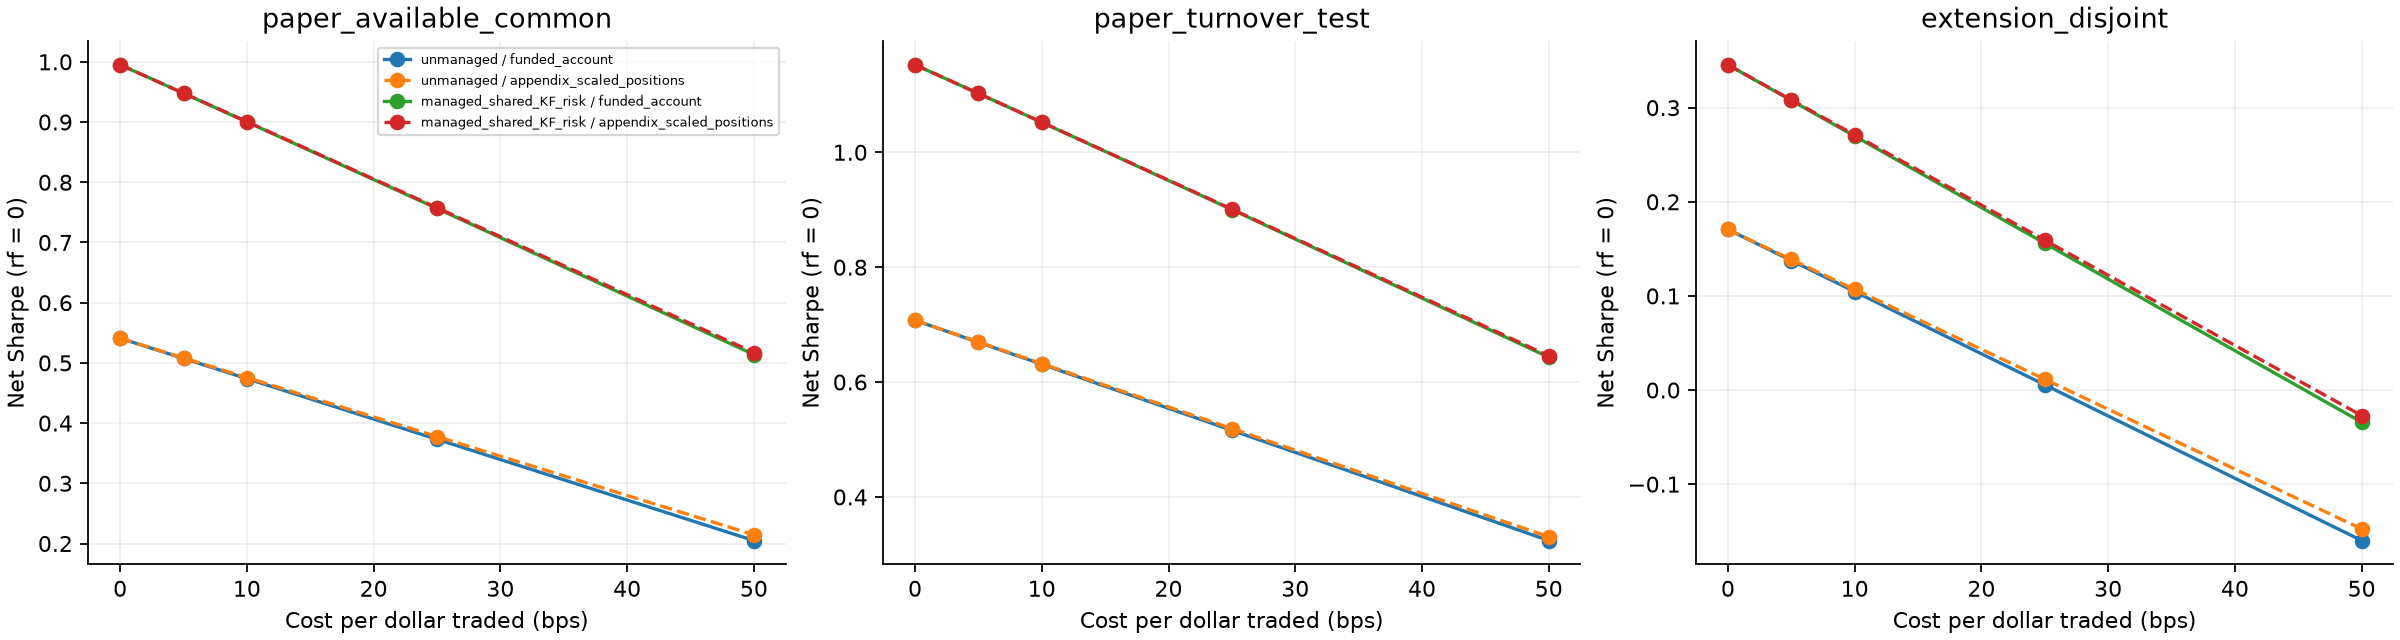

Table 6 - Funded-account cost sensitivity; all tested rates


,window,strategy,cost_bps_per_dollar,Annualized Mean Return,Annualized Volatility,Sharpe (rf=0),Maximum Drawdown,Annual trading cost
18,paper_available_common,unmanaged,0.000000,14.86%,27.48%,0.541,-95.44%,0.00%
19,paper_turnover_test,unmanaged,0.000000,16.08%,22.73%,0.707,-81.48%,0.00%
20,extension_disjoint,unmanaged,0.000000,4.63%,27.15%,0.171,-63.29%,0.00%
27,paper_available_common,unmanaged,5.000000,13.93%,27.46%,0.507,-95.85%,0.92%
28,paper_turnover_test,unmanaged,5.000000,15.20%,22.72%,0.669,-81.62%,0.87%
29,extension_disjoint,unmanaged,5.000000,3.73%,27.13%,0.138,-63.72%,0.89%
36,paper_available_common,unmanaged,10.000000,13.00%,27.45%,0.474,-96.22%,1.84%
37,paper_turnover_test,unmanaged,10.000000,14.32%,22.70%,0.631,-81.76%,1.74%
38,extension_disjoint,unmanaged,10.000000,2.84%,27.12%,0.105,-64.14%,1.79%
45,paper_available_common,unmanaged,25.000000,10.22%,27.40%,0.373,-97.15%,4.60%


In [5]:
baseline = metrics.loc[metrics.cost_bps_per_dollar.eq(BASELINE_COST_BPS) & metrics.method.isin(["funded_account", "appendix_scaled_positions"])]
show("Table 5 - Net performance at 10bp per dollar traded (20bp roundtrip diagnostic)",
     baseline[["method", *performance_columns, "Mean absolute traded notional", "Annual trading cost"]])
display(Image(filename=str(OUT / "cost_sensitivity.png")))
show("Table 6 - Funded-account cost sensitivity; all tested rates", metrics.loc[metrics.method.eq("funded_account"),
     ["window", "strategy", "cost_bps_per_dollar", "Annualized Mean Return", "Annualized Volatility", "Sharpe (rf=0)", "Maximum Drawdown", "Annual trading cost"]])

## 5. Significance cutoff and the paper's observations

The paper's 127/175bp figures are **roundtrip significance cutoffs**, not zero-mean break-even costs and not assumed trading fees. Here we solve for the roundtrip rate at which the net monthly mean's two-sided **IID Student-t** statistic falls to the 5% critical value; monthly cost variation is included in the net variance. Zero means already insignificant at no cost. This statistical diagnostic is not a claim to reproduce the authors' unavailable estimation code or a robust HAC test.

Interpret the cost-resilience claim only on the paper's distinct 1951-2010 turnover window. Compare direction, not exact numbers: higher Sharpe, lower volatility and crash losses, less negative skew and lower excess kurtosis; check increased average return separately. The extension can support some observations and contradict others. Shared KF risk makes this evidence conditional; it does not validate the missing independent stock-risk strategy.

In [6]:
cutoffs = pd.read_csv(OUT / "cutoffs.csv")
show("Table 7 - IID 95% significance cutoff, ROUNDTRIP basis points", cutoffs)
show("Table 8 - Directional observations at 10bp funded-account costs", pd.read_csv(OUT / "observations.csv"))
for window in WINDOWS:
    q = metrics.query("window == @window and method == 'funded_account' and cost_bps_per_dollar == 10").set_index("strategy")
    u, m = q.loc["unmanaged"], q.loc["managed_shared_KF_risk"]
    print(f"{window}: unmanaged -> managed Sharpe {u['Sharpe (rf=0)']:.3f} -> {m['Sharpe (rf=0)']:.3f}; "
          f"annual mean {u['Annualized Mean Return']:.2%} -> {m['Annualized Mean Return']:.2%}; "
          f"volatility {u['Annualized Volatility']:.2%} -> {m['Annualized Volatility']:.2%}; "
          f"worst month {u['Worst month']:.2%} -> {m['Worst month']:.2%}.")
print("Independent stock-risk full-window conclusion: unavailable; forecasts were not filled with cash.")

Table 7 - IID 95% significance cutoff, ROUNDTRIP basis points


,window,strategy,convention,IID_95pct_cutoff_roundtrip_bps
0,paper_available_common,unmanaged,scaled_positions,100.383422
1,paper_available_common,unmanaged,literal_eq10,100.383422
2,paper_turnover_test,unmanaged,scaled_positions,120.400214
3,paper_turnover_test,unmanaged,literal_eq10,120.400214
4,extension_disjoint,unmanaged,scaled_positions,0.000000
5,extension_disjoint,unmanaged,literal_eq10,0.000000
6,paper_available_common,managed_shared_KF_risk,scaled_positions,162.441666
7,paper_available_common,managed_shared_KF_risk,literal_eq10,93.935289
8,paper_turnover_test,managed_shared_KF_risk,scaled_positions,175.513261
9,paper_turnover_test,managed_shared_KF_risk,literal_eq10,136.404682


Table 8 - Directional observations at 10bp funded-account costs


,window,managed_minus_unmanaged_mean_pp,managed_minus_unmanaged_Sharpe,managed_volatility_lower,managed_worst_month_less_negative,managed_skewness_higher,managed_kurtosis_lower
0,paper_available_common,2.060908,0.426388,True,True,True,True
1,paper_turnover_test,3.610067,0.421249,True,True,True,True
2,extension_disjoint,0.378939,0.165152,True,True,True,True


paper_available_common: unmanaged -> managed Sharpe 0.474 -> 0.900; annual mean 13.00% -> 15.07%; volatility 27.45% -> 16.74%; worst month -78.26% -> -24.78%.
paper_turnover_test: unmanaged -> managed Sharpe 0.631 -> 1.052; annual mean 14.32% -> 17.93%; volatility 22.70% -> 17.04%; worst month -45.20% -> -17.00%.
extension_disjoint: unmanaged -> managed Sharpe 0.105 -> 0.270; annual mean 2.84% -> 3.22%; volatility 27.12% -> 11.92%; worst month -29.66% -> -11.58%.
Independent stock-risk full-window conclusion: unavailable; forecasts were not filled with cash.


### Findings from this run

- **Historical common window:** At 10bp per dollar traded, the funded account improves Sharpe from **0.474 to 0.900**, annual mean from **13.00% to 15.07%**, and worst monthly return from **-78.26% to -24.78%**. Lower volatility, less negative skew and lower excess kurtosis support the paper's qualitative observations under the stated conditional comparison.
- **Paper's turnover-test window (1951-03 to 2010-12):** Scaled-position half-turnover rises modestly from **71.32% to 73.40%**, close in direction to the paper's 74% to 75%. IID roundtrip significance cutoffs rise from **120.4bp to 175.5bp**, about **45.8% higher**, compared with the paper's reported 38%. Neither match is imposed or calibrated. The literal inverse-L managed turnover is **92.61%**, so it does not support the same small-increase statement; the formula ambiguity remains explicit.
- **2012-2025 extension:** At the same 10bp one-way rate, Sharpe improves from **0.105 to 0.270**, annual mean from **2.84% to 3.22%**, volatility from **27.12% to 11.92%**, and worst month from **-29.66% to -11.58%**. Tail-risk mitigation persists, but returns are weak and neither strategy's gross mean is significant in the IID cutoff test. This is weaker evidence than the historical sample, not a repeat of its profitability strength.
- **Unresolved:** No complete own-stock-risk month-end forecast is available under the checked daily policy. These tables cannot establish a full independent reconstructed-stock risk-management result. They establish a shared-risk controlled result; strict valuation coverage and stopped-account evidence remain visible above.


## 6. Validation and reproduction

The study checks artifact fingerprints, complete calendars, zero-cost account/gross reconciliation, stock-trade aggregation and fee identities. Unit tests cover entries/exits, leg switches, total-return leg drift, the inverse/multiplied scale distinction, no same-month return influence on current trades, unknown-return propagation and significance-cutoff units.

Run from the repository root:
```bash
.venv/bin/python -B scripts/run_stock_cost_study.py --cost-bps 0 5 10 25 50
.venv/bin/python -B -m pytest -p no:cacheprovider tests/ -q
```
Then rerun this notebook. Alternatively set `RERUN_STUDY=True` above. Monthly results and figures are in `outputs/05_stock_backtest`; licensed stock transitions and funded trades are in ignored `data/processed/05_stock_backtest`. The run manifest records all input/code fingerprints, conventions and cost settings. No network access is needed. Notebook 02 is unchanged.


In [7]:
for name in ["metrics.csv", "turnover.csv", "cutoffs.csv", "funded_monthly.csv", "appendix_monthly.csv", "observations.csv"]:
    assert (OUT / name).exists()
ledger = pd.read_csv(OUT / "funded_monthly.csv")
assert ledger.state.eq("ok").all() and ledger.net_return.notna().all()
np.testing.assert_allclose(ledger.transaction_cost, ledger.turnover * ledger.cost_bps_per_dollar / 10000, atol=1e-12)
for (_, _), group in ledger.groupby(["strategy", "cost_bps_per_dollar"]):
    assert len(group) == len(months)
print("Saved results verified; no missing forecasts or returns converted into cash.")
print("Manifest:", OUT / "run.json")

Saved results verified; no missing forecasts or returns converted into cash.
Manifest: /Users/guochuanchu/Downloads/momentum-risk-project/outputs/05_stock_backtest/run.json
